In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from pathlib import Path
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay
)

ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "Data" / "processed" / "telco_clean.csv")

In [7]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train,X_temp,y_train,y_temp=train_test_split(
    X,y,test_size=0.40,random_state=42,stratify=y
)

X_val,X_test,y_val,y_test=train_test_split(
    X_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp
)


In [8]:
import joblib

MODEL_PATH = ROOT / "models" / "best_model.joblib"
best_model = joblib.load(MODEL_PATH)

print("Model loaded successfully.")


Model loaded successfully.


In [9]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_prob):.4f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, test_prob):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)


Test ROC-AUC: 0.8321
Test PR-AUC:  0.6236

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.81      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.81      0.74      0.76      1409



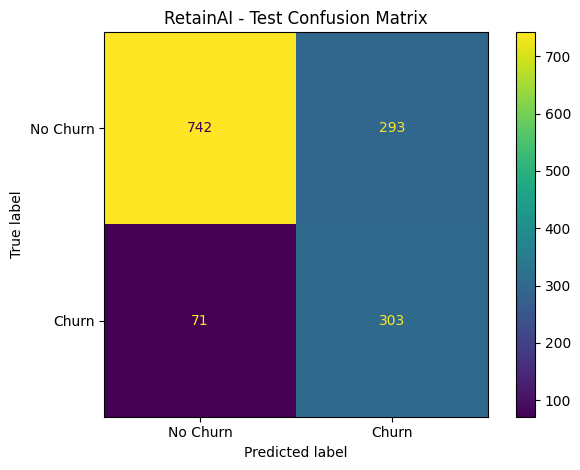

In [10]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No Churn", "Churn"]
)

plt.title("RetainAI - Test Confusion Matrix")
plt.tight_layout()
plt.show()